<a href="https://colab.research.google.com/github/pedroyoshikadogarcia/-GlobalSolution-02-2026---Modelagem-Linear-para-Aprendizado-de-Maquina---Citizen/blob/main/GlobalSolution_02_2026_Modelagem_Linear_para_Aprendizado_de_Maquina_Citizen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== RELATÓRIO DE DESEMPENHO: Regressão Logística ===
Acurácia: 0.8563

               precision    recall  f1-score   support

 Cidadão (PF)       0.88      0.94      0.91       260
 Empresa (PJ)       0.76      0.66      0.70        76
Órgão Público       0.67      0.33      0.44        12

     accuracy                           0.86       348
    macro avg       0.77      0.64      0.69       348
 weighted avg       0.85      0.86      0.85       348



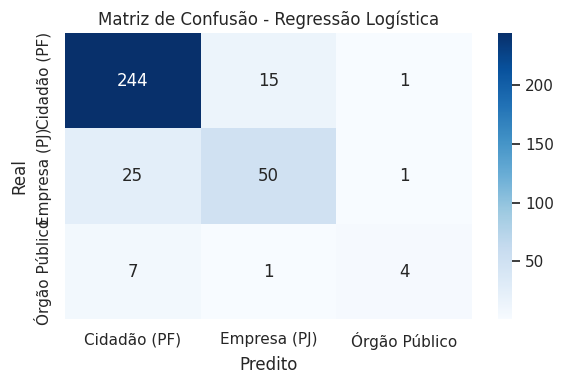

=== RELATÓRIO DE DESEMPENHO: SGDClassifier ===
Acurácia: 0.8333

               precision    recall  f1-score   support

 Cidadão (PF)       0.88      0.92      0.90       260
 Empresa (PJ)       0.68      0.62      0.65        76
Órgão Público       0.67      0.33      0.44        12

     accuracy                           0.83       348
    macro avg       0.74      0.62      0.66       348
 weighted avg       0.83      0.83      0.83       348



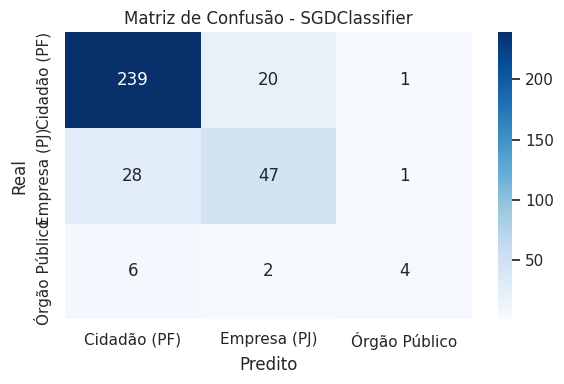

In [9]:
# ============================================================
# FIAP - Ciência da Computação
# Global Solution 2 - 2026
# Modelagem Linear para Aprendizado de Máquina (MLAM)
#
# Integrantes da Equipe:
# - Pedro Andreassa Zamai – RM: 569318
# - Pedro Yoshikado Garcia – RM: 570449
# - Thiago Maluf Hofmann – RM: 569852
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

df = pd.read_excel('BaseFinal_Censo.xlsx')

df_clean = df.dropna(subset=['Q005']).copy()
target_map = {1.0: 'Cidadão (PF)', 2.0: 'Empresa (PJ)', 3.0: 'Órgão Público'}
df_clean['Perfil_Usuario'] = df_clean['Q005'].map(target_map)

numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
excluded_keywords = ['T2','T3','T4','T5','T6','T7','T8','T9','T10','T11','id','token','Q005']
feature_cols = [c for c in numeric_cols if not any(k in c for k in excluded_keywords)]

X = df_clean[feature_cols].copy()
y = df_clean['Perfil_Usuario']

X = X.dropna(thresh=len(X)*0.5, axis=1)

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')

imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(max_iter=1000, random_state=42, C=1.0)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

sgd_model = SGDClassifier(loss='log_loss', max_iter=1000, random_state=42)
sgd_model.fit(X_train_scaled, y_train)
y_pred_sgd = sgd_model.predict(X_test_scaled)

def avaliar_modelo(y_true, y_pred, nome_modelo):
    print(f"=== RELATÓRIO DE DESEMPENHO: {nome_modelo} ===")
    print(f"Acurácia: {accuracy_score(y_true, y_pred):.4f}\n")
    print(classification_report(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred, labels=['Cidadão (PF)', 'Empresa (PJ)', 'Órgão Público'])
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Cidadão (PF)', 'Empresa (PJ)', 'Órgão Público'],
                yticklabels=['Cidadão (PF)', 'Empresa (PJ)', 'Órgão Público'])
    plt.title(f'Matriz de Confusão - {nome_modelo}')
    plt.xlabel('Predito')
    plt.ylabel('Real')
    plt.tight_layout()
    plt.show()

avaliar_modelo(y_test, y_pred_lr, "Regressão Logística")
avaliar_modelo(y_test, y_pred_sgd, "SGDClassifier")